In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio



In [2]:
data = sio.loadmat('/content/s1.mat')
print(data.keys())


dict_keys(['__header__', '__version__', '__globals__', 's1'])


In [3]:
s1 = data['s1']
print(s1.dtype)


[('train', 'O'), ('test', 'O')]


In [4]:
train = s1['train'][0][0]
print(train.dtype)


float64


In [5]:
type(train), train.shape


(numpy.ndarray, (11, 65282))

In [6]:
train[:5]


array([[ 0.00000000e+00,  3.90625000e-03,  7.81250000e-03, ...,
         2.54996094e+02,  2.55000000e+02,  2.55003906e+02],
       [ 1.09682865e-01,  8.79519960e-01,  2.27495705e+00, ...,
         4.18269845e+00,  8.24905654e+00,  1.14247062e+01],
       [-5.30831577e-01, -2.00985736e+00, -4.37474001e+00, ...,
        -1.67591063e+00,  3.11927854e+00,  7.05923594e+00],
       [ 1.06417497e+00,  5.15503477e+00,  1.12746417e+01, ...,
        -3.91667534e+00,  3.75130205e-01,  4.05063436e+00],
       [ 1.45685638e-01,  1.14153324e+00,  2.60966341e+00, ...,
        -5.29143570e+00, -6.49641132e-01,  3.16670125e+00]])

In [7]:
X = train
print(X.shape)


(11, 65282)


In [8]:
# Treat train data as EEG matrix
X = train

print("EEG shape:", X.shape)


EEG shape: (11, 65282)


In [9]:
eeg_signal = X[0, :]   # Channel 1


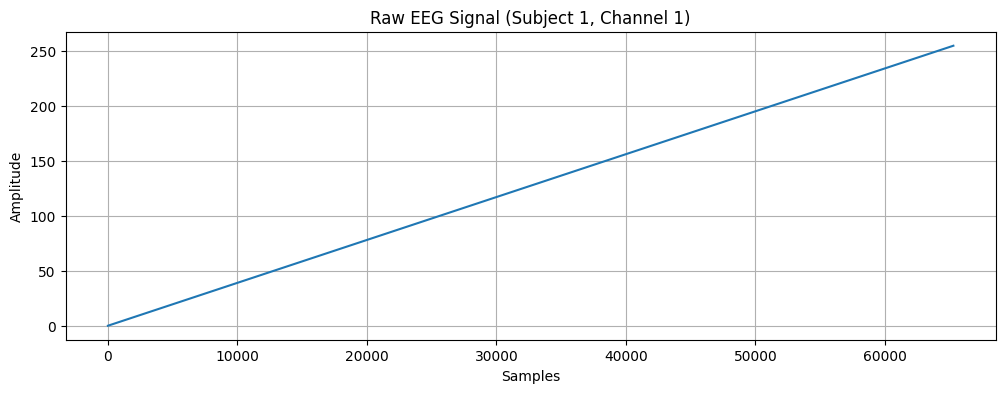

In [10]:
plt.figure(figsize=(12,4))
plt.plot(eeg_signal)
plt.title("Raw EEG Signal (Subject 1, Channel 1)")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()


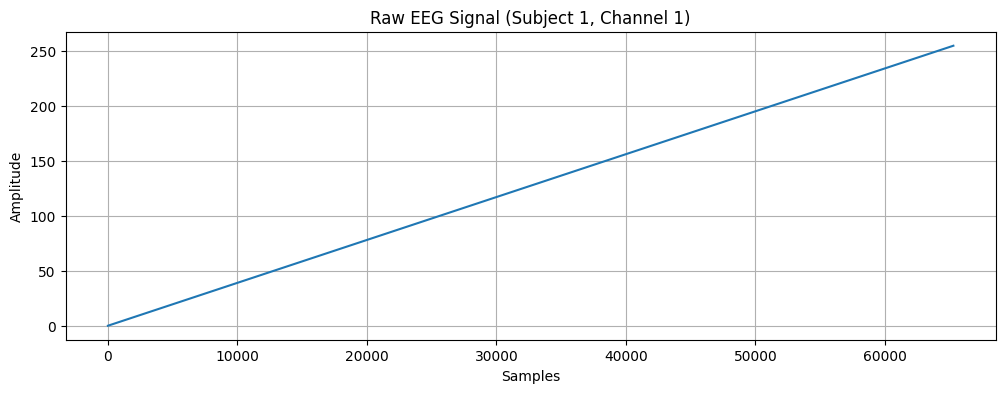

In [11]:
plt.figure(figsize=(12,4))
plt.plot(eeg_signal)
plt.title("Raw EEG Signal (Subject 1, Channel 1)")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.grid(True)
plt.savefig("raw_eeg_subject1_channel1.png", dpi=300)
plt.show()


Bandpass filtering

In [12]:
from scipy.signal import butter, filtfilt


In [13]:
def bandpass_filter(signal, fs, lowcut=0.1, highcut=30, order=4):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')
    filtered_signal = filtfilt(b, a, signal)
    return filtered_signal


In [14]:
fs = 240  # sampling frequency in Hz


In [15]:
filtered_eeg = bandpass_filter(eeg_signal, fs)


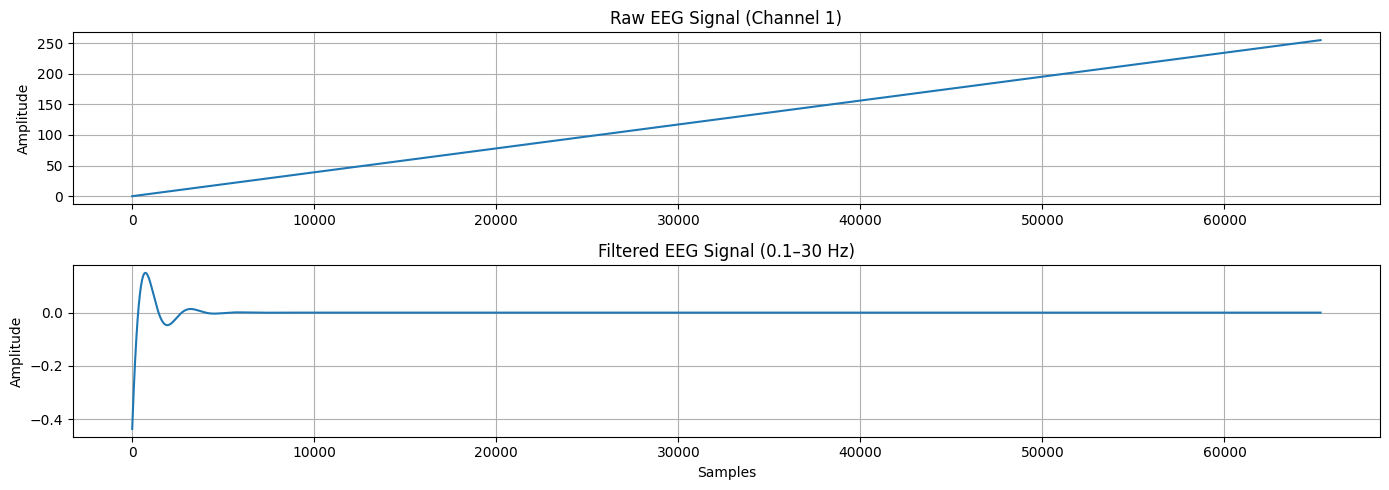

In [16]:
plt.figure(figsize=(14,5))

plt.subplot(2,1,1)
plt.plot(eeg_signal)
plt.title("Raw EEG Signal (Channel 1)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(2,1,2)
plt.plot(filtered_eeg)
plt.title("Filtered EEG Signal (0.1–30 Hz)")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.grid(True)

plt.tight_layout()
plt.show()
